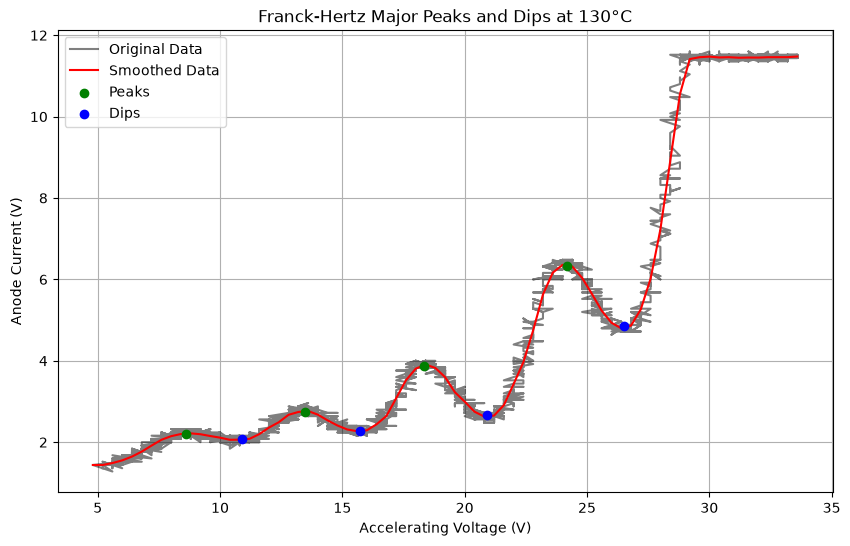


Peak Voltages: [ 8.59 13.46 18.32 24.18]
Spacing Between Successive Peaks (V): [4.87 4.86 5.86]

Dip Voltages: [10.91 15.72 20.92 26.51]
Spacing Between Successive Dips (V): [4.81 5.2  5.59]



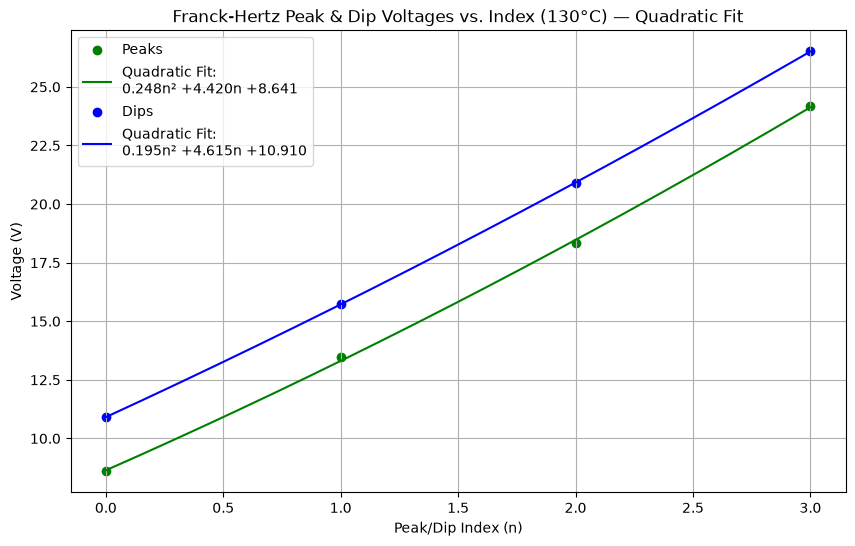

                    === Peaks ===

        Ea (eV)         λ (m)      Eprime (eV)
      4.42 ± 0.35      0.00045        8.64

                    === Dips ===

        Ea (eV)         λ (m)      Eprime (eV)
      4.62 ± 0.00      0.00034       10.91


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from statsmodels.nonparametric.smoothers_lowess import lowess
#-------------------------------------------------------------------------------
# File
filepath = 'FH - T130.csv' 
df = pd.read_csv(filepath, header=0, index_col=None)
df.head()

# Turn into array
AC_data = np.array(df['Anode Current (V)'])
AV_data = np.array(df['Accelerating Voltage (V)'])

# Sort by voltage
idx = np.argsort(AV_data)
AV_sorted = AV_data[idx]
AC_sorted = AC_data[idx]

# Average accelerating voltage duplicates 
df_avg = pd.DataFrame({'AV': AV_sorted, 'AC': AC_sorted}).groupby('AV', as_index=False).mean()
AV_unique = df_avg['AV'].values
AC_unique = df_avg['AC'].values

# Lowess smoothed values
smooth_values = lowess(AC_unique, AV_unique, frac=0.05, return_sorted=True)
x_s = smooth_values[:, 0]
y_s = smooth_values[:, 1]

# Manually identified peaks and dips from LOWESS-smoothed data
x_peaks = np.array([8.59, 13.46, 18.32, 24.18])
y_peaks = np.array([2.20565808, 2.73196263, 3.87504623, 6.32563055])
x_dips = np.array([10.91, 15.72, 20.92, 26.51])
y_dips = np.array([2.06851157, 2.28676589, 2.67318653, 4.8493327])

# Spacing
peak_spacing = np.diff(x_peaks)
dip_spacing = np.diff(x_dips)

# Plotting figure
plt.figure(figsize=(10, 6))
plt.title("Franck-Hertz Major Peaks and Dips at 130°C")
plt.xlabel('Accelerating Voltage (V)')
plt.ylabel('Anode Current (V)')
plt.plot(AV_data, AC_data, 'black', alpha=0.5, label='Original Data')
plt.plot(smooth_values[:, 0], smooth_values[:, 1], 'red', label='Smoothed Data', linestyle='-')
plt.scatter(x_peaks, y_peaks, color='green', label='Peaks', zorder=10)
plt.scatter(x_dips, y_dips, color='blue', label='Dips', zorder=10)
plt.legend()
plt.grid(True)
plt.show()

print("")

# Print results
print("Peak Voltages:", x_peaks)
print("Spacing Between Successive Peaks (V):", peak_spacing)

print("")

print("Dip Voltages:", x_dips)
print("Spacing Between Successive Dips (V):", dip_spacing)

print("")

#-------------------------------------------------------------------------------
# Experimental data
n_peaks = np.array([0, 1, 2, 3])

n_dips = np.array([0, 1, 2, 3])

# Electrode spacing
L = 0.008      # meters

# Quadratic model
def quadratic(n, A, B, C):
    return A * n**2 + B * n + C

# Plotting
n_plot = np.linspace(0, 3, 300)

#  Fit peaks
popt_peaks, pcov_peaks = curve_fit(quadratic, n_peaks, x_peaks, p0=[1, 1, 1])
A_p, B_p, C_p = popt_peaks  

# Variances & covariance
sa2_p = pcov_peaks[0, 0]   
sb2_p = pcov_peaks[1, 1]  
sab_p = pcov_peaks[0, 1]   

# Linear coefficient and standard error (peaks)
slope_peaks= B_p
slope_peaks_err= np.sqrt(sb2_p)

# Fit dips
popt_dips, pcov_dips = curve_fit(quadratic, n_dips, x_dips, p0=[1, 1, 1])
A_d, B_d, C_d = popt_dips 

# Variances & covariance
sa2_d = pcov_dips[0, 0]   # var(a)
sb2_d = pcov_dips[1, 1]   # var(b)
sab_d = pcov_dips[0, 1]   # cov(a, b)

# Linear coefficient and standard error (dips)
slope_dips = B_d
slope_dips_err = np.sqrt(sb2_d)

# Physical quantities
Ea_peaks = B_p                     # in volts
Ea_dips = B_d                      # in volts
lambda_peaks = (A_p / B_p) * L     # in meters
lambda_dips =  (A_d / B_d) * L     # in meters
Eprime_peaks = C_p                 # in volts
Eprime_dips = C_d                  # in volts

# Peaks plot
V_fit_peaks = quadratic(n_plot, *popt_peaks)

# Dips plot
V_fit_dips = quadratic(n_plot, *popt_dips)

# Equation (peaks)
eq_peaks = (
    "Quadratic Fit:\n"
    f"{A_p:.3f}n² {B_p:+.3f}n {C_p:+.3f}"
)

# Equation (dips)
eq_dips = (
    "Quadratic Fit:\n"
    f"{A_d:.3f}n² {B_d:+.3f}n {C_d:+.3f}"
)

# Plotting
plt.figure(figsize=(10, 6))
# Peaks
plt.scatter(n_peaks, x_peaks, color='green', label="Peaks")
plt.plot(n_plot, V_fit_peaks, color='green', label=eq_peaks)
# Dips
plt.scatter(n_dips, x_dips, color='blue', label="Dips")
plt.plot(n_plot, V_fit_dips, color='blue', label=eq_dips)
plt.xlabel("Peak/Dip Index (n)")
plt.ylabel("Voltage (V)")
plt.title("Franck-Hertz Peak & Dip Voltages vs. Index (130°C) — Quadratic Fit")
plt.legend()
plt.grid(True)
plt.show()

# --- Print results in table format ---
print("                    === Peaks ===")
print("")
print(f"{'Ea (eV)':>15} {'λ (m)':>13} {'Eprime (eV)':>16}")
print(f"{Ea_peaks:10.2f} ± {slope_peaks_err:.2f} {abs(lambda_peaks):12.5f} {Eprime_peaks:11.2f}\n")

print("                    === Dips ===")
print("")
print(f"{'Ea (eV)':>15} {'λ (m)':>13} {'Eprime (eV)':>16}")
print(f"{Ea_dips:10.2f} ± {slope_dips_err:.2f} {abs(lambda_dips):12.5f} {Eprime_dips:11.2f}")

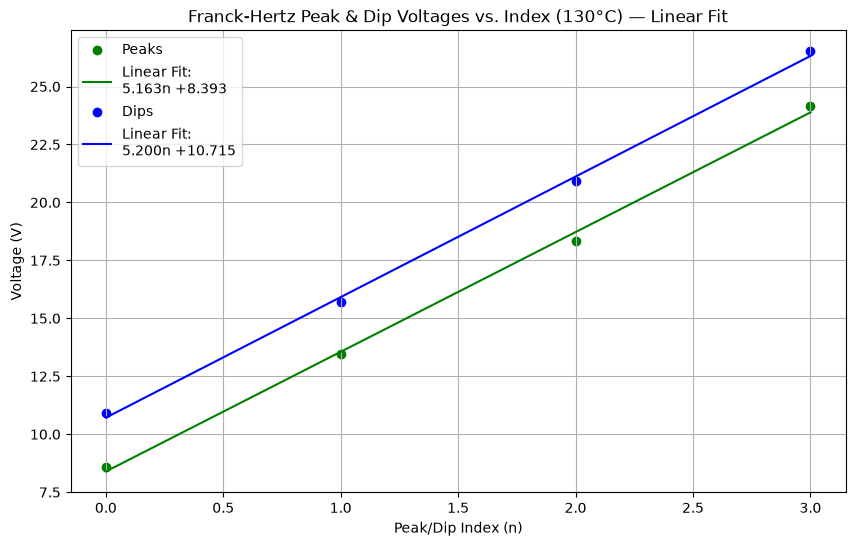

             === Peaks ===

        Ea (eV)       Eprime (eV)
      5.16 ± 0.17         8.39

             === Dips ===

        Ea (eV)       Eprime (eV)
      5.20 ± 0.12        10.71


In [2]:
# Experimental data
x_peaks = np.array([8.59, 13.46, 18.32, 24.18])
x_dips = np.array([10.91, 15.72, 20.92, 26.51])
n_peaks = np.array([0, 1, 2, 3])
n_dips = np.array([0, 1, 2, 3])

# linear model
def linear(n, m, b):
    return m*n + b

# Plotting
n_plot = np.linspace(0, 3, 300)

#  Fit peaks
popt_peaks, pcov_peaks = curve_fit(linear, n_peaks, x_peaks)
m_p, b_p = popt_peaks  

# Variances & covariance
sm2_p = pcov_peaks[0, 0]   
sb2_p = pcov_peaks[1, 1]  
smb_p = pcov_peaks[0, 1]   

# Slope and standard error (peaks)
slope_peaks= m_p
slope_peaks_err= np.sqrt(sm2_p)

#  Fit dips
popt_dips, pcov_dips = curve_fit(linear, n_dips, x_dips)
m_d, b_d = popt_dips  

# Variances & covariance
sm2_d = pcov_dips[0, 0]   
sb2_d = pcov_dips[1, 1]  
smb_d = pcov_dips[0, 1]   

# Slope and standard error (dips)
slope_dips= m_d
slope_dips_err= np.sqrt(sm2_d)

V_fit_peaks = linear(n_plot, *popt_peaks)

V_fit_dips = linear(n_plot, *popt_dips)

# Equation (peaks)
eq_peaks = (
    "Linear Fit:\n"
    f"{m_p:.3f}n {b_p:+.3f}"
)

# Equation (dips)
eq_dips = (
    "Linear Fit:\n"
    f"{m_d:.3f}n {b_d:+.3f}"
)

# Plotting
plt.figure(figsize=(10, 6))
# Peaks
plt.scatter(n_peaks, x_peaks, color='green', label="Peaks")
plt.plot(n_plot, V_fit_peaks, color='green', label=eq_peaks)
# Dips
plt.scatter(n_dips, x_dips, color='blue', label="Dips")
plt.plot(n_plot, V_fit_dips, color='blue', label=eq_dips)
plt.xlabel("Peak/Dip Index (n)")
plt.ylabel("Voltage (V)")
plt.title("Franck-Hertz Peak & Dip Voltages vs. Index (130°C) — Linear Fit")
plt.grid(True)
plt.legend()
plt.show()

# --- Print results in table format ---
print("             === Peaks ===")
print("")
print(f"{'Ea (eV)':>15} {'Eprime (eV)':>17}")
print(f"{m_p:10.2f} ± {slope_peaks_err:.2f} {b_p:12.2f}\n")

print("             === Dips ===")
print("")
print(f"{'Ea (eV)':>15} {'Eprime (eV)':>17}")
print(f"{m_d:10.2f} ± {slope_dips_err:.2f} {b_d:12.2f}")

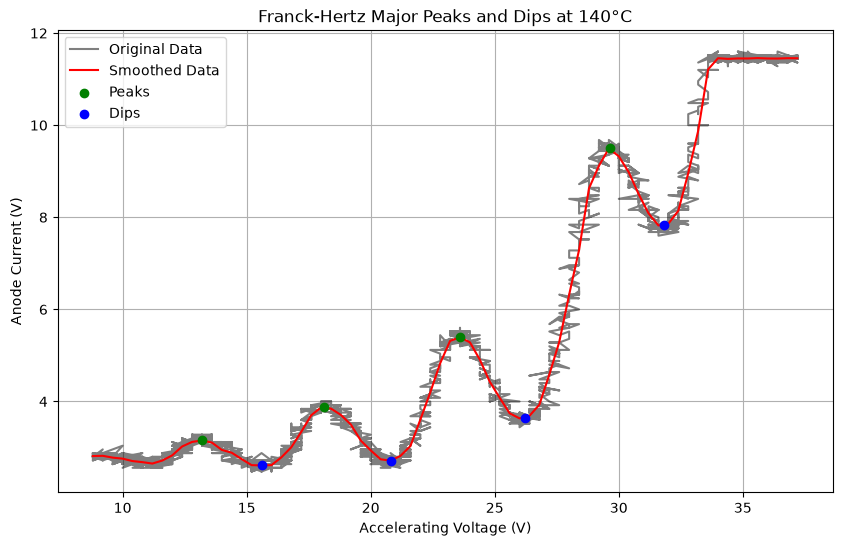


Peak Voltages: [13.2  18.13 23.6  29.65]
Spacing Between Successive Peaks (V): [4.93 5.47 6.05]

Dip Voltages: [15.6  20.8  26.22 31.84]
Spacing Between Successive Dips (V): [5.2  5.42 5.62]



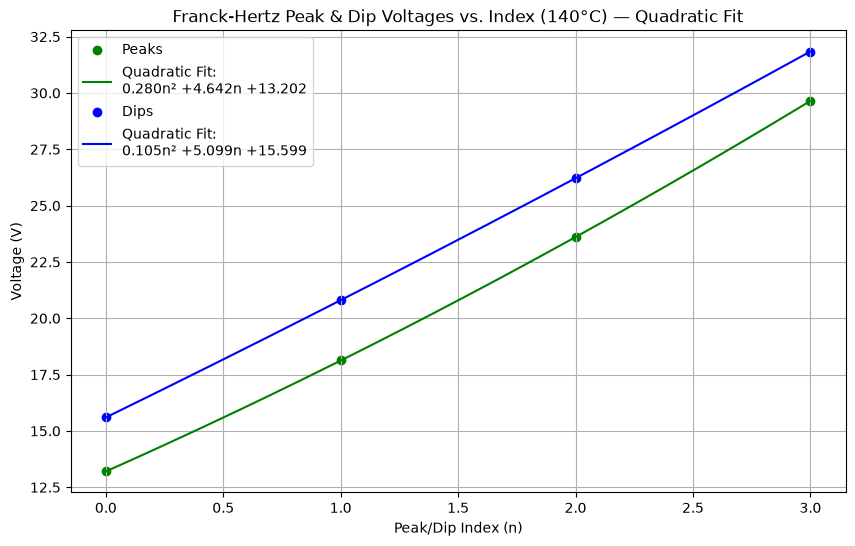

                    === Peaks ===

        Ea (eV)         λ (m)      Eprime (eV)
      4.64 ± 0.01      0.00048       13.20

                    === Dips ===

        Ea (eV)         λ (m)      Eprime (eV)
      5.10 ± 0.01      0.00016       15.60


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from statsmodels.nonparametric.smoothers_lowess import lowess
#-------------------------------------------------------------------------------
# File
filepath = 'FH - T140.csv' 
df = pd.read_csv(filepath, header=0, index_col=None)
df.head()

# Turn into array
AC_data = np.array(df['Anode Current (V)'])
AV_data = np.array(df['Accelerating Voltage (V)'])

# Sort by voltage
idx = np.argsort(AV_data)
AV_sorted = AV_data[idx]
AC_sorted = AC_data[idx]

# Average accelerating voltage duplicates 
df_avg = pd.DataFrame({'AV': AV_sorted, 'AC': AC_sorted}).groupby('AV', as_index=False).mean()
AV_unique = df_avg['AV'].values
AC_unique = df_avg['AC'].values

# Lowess smoothed values
smooth_values = lowess(AC_unique, AV_unique, frac=0.05, return_sorted=True)
x_s = smooth_values[:, 0]
y_s = smooth_values[:, 1]

# Manually identified peaks and dips from LOWESS-smoothed data
x_peaks = np.array([13.20, 18.13, 23.60, 29.65])
y_peaks = np.array([3.15529412, 3.87200000, 5.39294118, 9.49411765])
x_dips = np.array([15.60, 20.80, 26.22, 31.84])
y_dips = np.array([2.61263158, 2.71515152, 3.63384615, 7.82222222])

# Spacing
peak_spacing = np.diff(x_peaks)
dip_spacing = np.diff(x_dips)

# Plotting figure
plt.figure(figsize=(10, 6))
plt.title("Franck-Hertz Major Peaks and Dips at 140°C")
plt.xlabel('Accelerating Voltage (V)')
plt.ylabel('Anode Current (V)')
plt.plot(AV_data, AC_data, 'black', alpha=0.5, label='Original Data')
plt.plot(smooth_values[:, 0], smooth_values[:, 1], 'red', label='Smoothed Data', linestyle='-')
plt.scatter(x_peaks, y_peaks, color='green', label='Peaks', zorder=10)
plt.scatter(x_dips, y_dips, color='blue', label='Dips', zorder=10)
plt.legend()
plt.grid(True)
plt.show()

print("")

# Print results
print("Peak Voltages:", x_peaks)
print("Spacing Between Successive Peaks (V):", peak_spacing)

print("")

print("Dip Voltages:", x_dips)
print("Spacing Between Successive Dips (V):", dip_spacing)

print("")
#-------------------------------------------------------------------------------
# Experimental data
n_peaks = np.array([0, 1, 2, 3])
n_dips = np.array([0, 1, 2, 3])

# Electrode spacing
L = 0.008      # meters

# Quadratic model
def quadratic(n, A, B, C):
    return A * n**2 + B * n + C

# Plotting
n_plot = np.linspace(0, 3, 300)

#  Fit peaks
popt_peaks, pcov_peaks = curve_fit(quadratic, n_peaks, x_peaks, p0=[1, 1, 1])
A_p, B_p, C_p = popt_peaks  

# Variances & covariance
sa2_p = pcov_peaks[0, 0]   
sb2_p = pcov_peaks[1, 1]  
sab_p = pcov_peaks[0, 1]   

# Slope peaks
slope_peaks= B_p
slope_peaks_err= np.sqrt(sb2_p)

# Fit dips
popt_dips, pcov_dips = curve_fit(quadratic, n_dips, x_dips, p0=[1, 1, 1])
A_d, B_d, C_d = popt_dips 

# Variances & covariance
sa2_d = pcov_dips[0, 0]   # var(a)
sb2_d = pcov_dips[1, 1]   # var(b)
sab_d = pcov_dips[0, 1]   # cov(a, b)

# Slope dips
slope_dips = B_d
slope_dips_err = np.sqrt(sb2_d)

# Physical quantities
Ea_peaks = B_p                     # in volts
Ea_dips = B_d                      # in volts
lambda_peaks = (A_p / B_p) * L     # in meters
lambda_dips =  (A_d / B_d) * L     # in meters
Eprime_peaks = C_p                 # in volts
Eprime_dips = C_d                  # in volts

# Peaks plot
V_fit_peaks = quadratic(n_plot, *popt_peaks)

# Dips plot
V_fit_dips = quadratic(n_plot, *popt_dips)

# Equation (peaks)
eq_peaks = (
    "Quadratic Fit:\n"
    f"{A_p:.3f}n² {B_p:+.3f}n {C_p:+.3f}"
)

# Equation (dips)
eq_dips = (
    "Quadratic Fit:\n"
    f"{A_d:.3f}n² {B_d:+.3f}n {C_d:+.3f}"
)

# Plotting
plt.figure(figsize=(10, 6))
# Peaks
plt.scatter(n_peaks, x_peaks, color='green', label="Peaks")
plt.plot(n_plot, V_fit_peaks, color='green', label=eq_peaks)
# Dips
plt.scatter(n_dips, x_dips, color='blue', label="Dips")
plt.plot(n_plot, V_fit_dips, color='blue', label=eq_dips)
plt.xlabel("Peak/Dip Index (n)")
plt.ylabel("Voltage (V)")
plt.title("Franck-Hertz Peak & Dip Voltages vs. Index (140°C) — Quadratic Fit")
plt.legend()
plt.grid(True)
plt.show()

# --- Print results in table format ---
print("                    === Peaks ===")
print("")
print(f"{'Ea (eV)':>15} {'λ (m)':>13} {'Eprime (eV)':>16}")
print(f"{Ea_peaks:10.2f} ± {slope_peaks_err:.2f} {abs(lambda_peaks):12.5f} {Eprime_peaks:11.2f}\n")

print("                    === Dips ===")
print("")
print(f"{'Ea (eV)':>15} {'λ (m)':>13} {'Eprime (eV)':>16}")
print(f"{Ea_dips:10.2f} ± {slope_dips_err:.2f} {abs(lambda_dips):12.5f} {Eprime_dips:11.2f}")

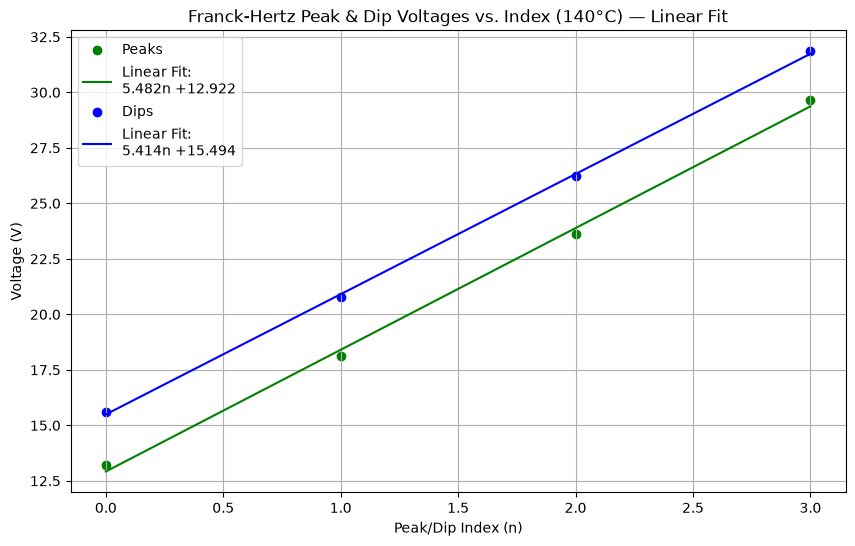

             === Peaks ===

        Ea (eV)       Eprime (eV)
      5.48 ± 0.18        12.92

             === Dips ===

        Ea (eV)       Eprime (eV)
      5.41 ± 0.07        15.49


In [4]:
# Experimental data
x_peaks = np.array([13.20, 18.13, 23.60, 29.65])
x_dips = np.array([15.60, 20.80, 26.22, 31.84])
n_peaks = np.array([0, 1, 2, 3])
n_dips = np.array([0, 1, 2, 3])

# linear model
def linear(n, m, b):
    return m*n + b

# Plotting
n_plot = np.linspace(0, 3, 300)

#  Fit peaks
popt_peaks, pcov_peaks = curve_fit(linear, n_peaks, x_peaks)
m_p, b_p = popt_peaks  

# Variances & covariance
sm2_p = pcov_peaks[0, 0]   
sb2_p = pcov_peaks[1, 1]  
smb_p = pcov_peaks[0, 1]   

# Slope and standard error (peaks)
slope_peaks= m_p
slope_peaks_err= np.sqrt(sm2_p)

#  Fit dips
popt_dips, pcov_dips = curve_fit(linear, n_dips, x_dips)
m_d, b_d = popt_dips  

# Variances & covariance
sm2_d = pcov_dips[0, 0]   
sb2_d = pcov_dips[1, 1]  
smb_d = pcov_dips[0, 1]   

# Slope and standard error (dips)
slope_dips= m_d
slope_dips_err= np.sqrt(sm2_d)

V_fit_peaks = linear(n_plot, *popt_peaks)

V_fit_dips = linear(n_plot, *popt_dips)

# Equation (peaks)
eq_peaks = (
    "Linear Fit:\n"
    f"{m_p:.3f}n {b_p:+.3f}"
)

# Equation (dips)
eq_dips = (
    "Linear Fit:\n"
    f"{m_d:.3f}n {b_d:+.3f}"
)

# Plotting
plt.figure(figsize=(10, 6))
# Peaks
plt.scatter(n_peaks, x_peaks, color='green', label="Peaks")
plt.plot(n_plot, V_fit_peaks, color='green', label=eq_peaks)
# Dips
plt.scatter(n_dips, x_dips, color='blue', label="Dips")
plt.plot(n_plot, V_fit_dips, color='blue', label=eq_dips)
plt.xlabel("Peak/Dip Index (n)")
plt.ylabel("Voltage (V)")
plt.title("Franck-Hertz Peak & Dip Voltages vs. Index (140°C) — Linear Fit")
plt.grid(True)
plt.legend()
plt.show()

# --- Print results in table format ---
print("             === Peaks ===")
print("")
print(f"{'Ea (eV)':>15} {'Eprime (eV)':>17}")
print(f"{m_p:10.2f} ± {slope_peaks_err:.2f} {b_p:12.2f}\n")

print("             === Dips ===")
print("")
print(f"{'Ea (eV)':>15} {'Eprime (eV)':>17}")
print(f"{m_d:10.2f} ± {slope_dips_err:.2f} {b_d:12.2f}")

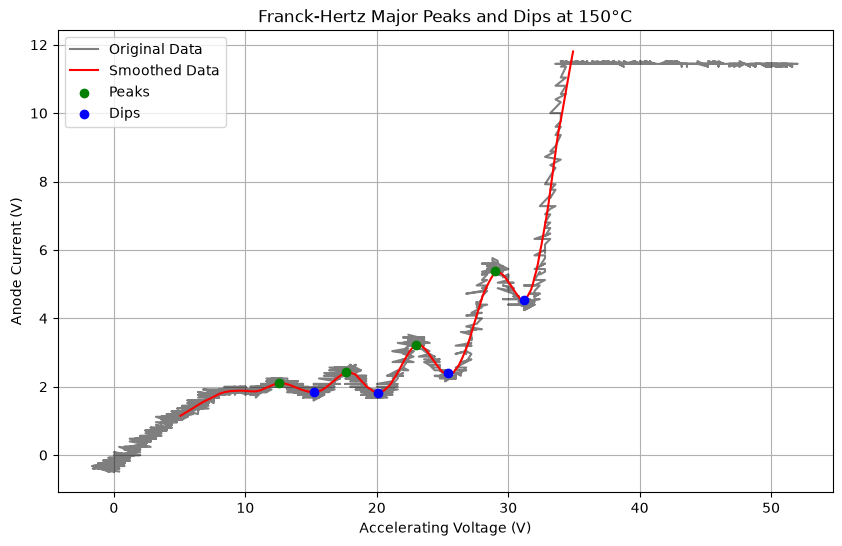


Peak Voltages: [12.54 17.63 23.01 29.01]
Spacing Between Successive Peaks (V): [5.09 5.38 6.  ]

Dip Voltages: [15.2  20.13 25.43 31.22]
Spacing Between Successive Dips (V): [4.93 5.3  5.79]



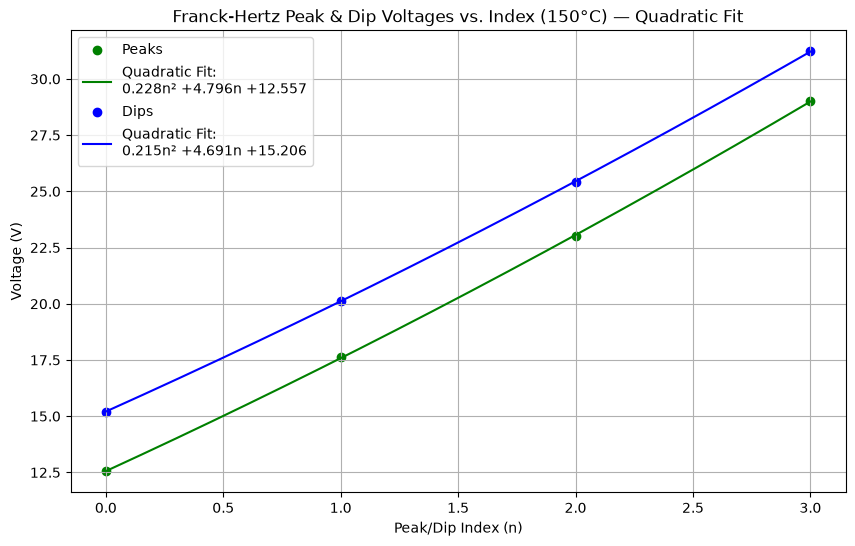

                    === Peaks ===

        Ea (eV)         λ (m)      Eprime (eV)
      4.80 ± 0.12      0.00038       12.56

                    === Dips ===

        Ea (eV)         λ (m)      Eprime (eV)
      4.69 ± 0.04      0.00037       15.21


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit
from statsmodels.nonparametric.smoothers_lowess import lowess
#-------------------------------------------------------------------------------
# File
filepath = 'FH - T150.csv' 
df = pd.read_csv(filepath, header=0, index_col=None)
df.head()

# Turn into array
AC_data = np.array(df['Anode Current (V)'])
AV_data = np.array(df['Accelerating Voltage (V)'])

# Sort by voltage
idx = np.argsort(AV_data)
AV_sorted = AV_data[idx]
AC_sorted = AC_data[idx]

# Savitzky-Golay smoothing
AC_smoothie = savgol_filter(AC_sorted, window_length=11, polyorder=4)
AV_smoothie = savgol_filter(AV_sorted, window_length=11, polyorder=4)

# Restrict data to the voltage interval of interest (5–35 V)
trim_mask = (AV_smoothie > 5) & (AV_smoothie < 35)
AV_trim = AV_smoothie[trim_mask]
AC_trim = AC_smoothie[trim_mask]

# Lowess smoothed values
smooth_values = lowess(AC_trim, AV_trim, frac=0.07, return_sorted=True)
x_s = smooth_values[:, 0]
y_s = smooth_values[:, 1]

# Manually identified peaks and dips from LOWESS-smoothed data
x_peaks = np.array([12.54, 17.63, 23.01, 29.01])
y_peaks = np.array([2.09776124, 2.4192928, 3.21152953, 5.37095559])
x_dips = np.array([15.20, 20.13, 25.43, 31.22])
y_dips = np.array([1.8380892, 1.81914721, 2.40432569, 4.52972836])

# Spacing
peak_spacing = np.diff(x_peaks)
dip_spacing = np.diff(x_dips)

# Plotting figure
plt.figure(figsize=(10, 6))
plt.title("Franck-Hertz Major Peaks and Dips at 150°C")
plt.xlabel('Accelerating Voltage (V)')
plt.ylabel('Anode Current (V)')
plt.plot(AV_data, AC_data, 'black', alpha=0.5, label='Original Data')
plt.plot(smooth_values[:, 0], smooth_values[:, 1], 'red', label='Smoothed Data', linestyle='-')
plt.scatter(x_peaks, y_peaks, color='green', label='Peaks', zorder=10)
plt.scatter(x_dips, y_dips, color='blue', label='Dips', zorder=10)
plt.legend()
plt.grid(True)
plt.show()

print("")

# Print results
print("Peak Voltages:", x_peaks)
print("Spacing Between Successive Peaks (V):", peak_spacing)

print("")

print("Dip Voltages:", x_dips)
print("Spacing Between Successive Dips (V):", dip_spacing)

print("")
#-------------------------------------------------------------------------------"
# Experimental data
n_peaks = np.array([0, 1, 2, 3])

n_dips = np.array([0, 1, 2, 3])

# Electrode spacing
L = 0.008      # meters

# Quadratic model
def quadratic(n, A, B, C):
    return A * n**2 + B * n + C

# Plotting
n_plot = np.linspace(0, 3, 300)

#  Fit peaks
popt_peaks, pcov_peaks = curve_fit(quadratic, n_peaks, x_peaks, p0=[1, 1, 1])
A_p, B_p, C_p = popt_peaks  

# Variances & covariance
sa2_p = pcov_peaks[0, 0]   
sb2_p = pcov_peaks[1, 1]  
sab_p = pcov_peaks[0, 1]   

# Linear coefficient and standard error (peaks)
slope_peaks= B_p
slope_peaks_err= np.sqrt(sb2_p)

# Fit dips
popt_dips, pcov_dips = curve_fit(quadratic, n_dips, x_dips, p0=[1, 1, 1])
A_d, B_d, C_d = popt_dips 

# Variances & covariance
sa2_d = pcov_dips[0, 0]   # var(a)
sb2_d = pcov_dips[1, 1]   # var(b)
sab_d = pcov_dips[0, 1]   # cov(a, b)

# Linear coefficient and standard error (dips)
slope_dips = B_d
slope_dips_err = np.sqrt(sb2_d)

# Physical quantities
Ea_peaks = B_p                     # in volts
Ea_dips = B_d                      # in volts
lambda_peaks = (A_p / B_p) * L     # in meters
lambda_dips =  (A_d / B_d) * L     # in meters
Eprime_peaks = C_p                 # in volts
Eprime_dips = C_d                  # in volts

# Peaks plot
V_fit_peaks = quadratic(n_plot, *popt_peaks)

# Dips plot
V_fit_dips = quadratic(n_plot, *popt_dips)

# Equation (peaks)
eq_peaks = (
    "Quadratic Fit:\n"
    f"{A_p:.3f}n² {B_p:+.3f}n {C_p:+.3f}"
)

# Equation (dips)
eq_dips = (
    "Quadratic Fit:\n"
    f"{A_d:.3f}n² {B_d:+.3f}n {C_d:+.3f}"
)

# Plotting
plt.figure(figsize=(10, 6))
# Peaks
plt.scatter(n_peaks, x_peaks, color='green', label="Peaks")
plt.plot(n_plot, V_fit_peaks, color='green', label=eq_peaks)
# Dips
plt.scatter(n_dips, x_dips, color='blue', label="Dips")
plt.plot(n_plot, V_fit_dips, color='blue', label=eq_dips)
plt.xlabel("Peak/Dip Index (n)")
plt.ylabel("Voltage (V)")
plt.title("Franck-Hertz Peak & Dip Voltages vs. Index (150°C) — Quadratic Fit")
plt.legend()
plt.grid(True)
plt.show()

# --- Print results in table format ---
print("                    === Peaks ===")
print("")
print(f"{'Ea (eV)':>15} {'λ (m)':>13} {'Eprime (eV)':>16}")
print(f"{Ea_peaks:10.2f} ± {slope_peaks_err:.2f} {abs(lambda_peaks):12.5f} {Eprime_peaks:11.2f}\n")

print("                    === Dips ===")
print("")
print(f"{'Ea (eV)':>15} {'λ (m)':>13} {'Eprime (eV)':>16}")
print(f"{Ea_dips:10.2f} ± {slope_dips_err:.2f} {abs(lambda_dips):12.5f} {Eprime_dips:11.2f}")

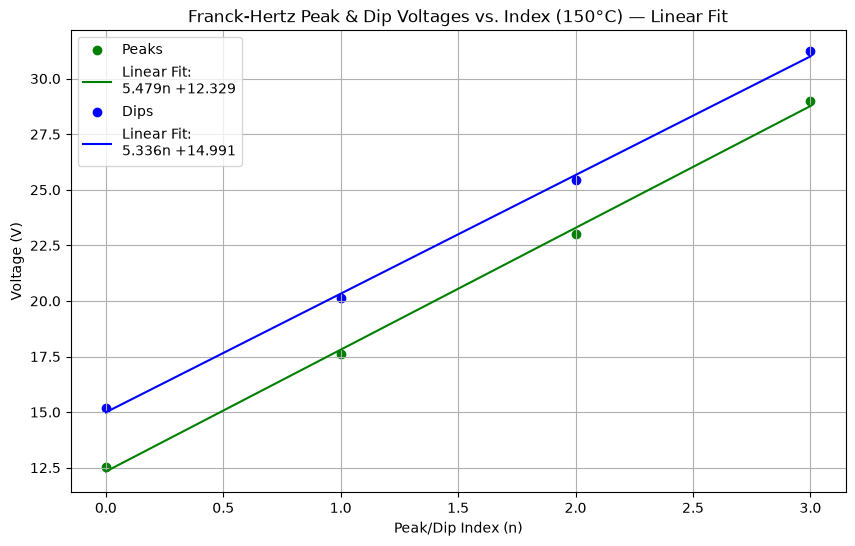

             === Peaks ===

        Ea (eV)       Eprime (eV)
      5.48 ± 0.15        12.33

             === Dips ===

        Ea (eV)       Eprime (eV)
      5.34 ± 0.14        14.99


In [6]:
# Experimental data
x_peaks = np.array([12.54, 17.63, 23.01, 29.01])
x_dips = np.array([15.20, 20.13, 25.43, 31.22])
n_peaks = np.array([0, 1, 2, 3])
n_dips = np.array([0, 1, 2, 3])

# linear model
def linear(n, m, b):
    return m*n + b

# Plotting
n_plot = np.linspace(0, 3, 300)

#  Fit peaks
popt_peaks, pcov_peaks = curve_fit(linear, n_peaks, x_peaks)
m_p, b_p = popt_peaks  

# Variances & covariance
sm2_p = pcov_peaks[0, 0]   
sb2_p = pcov_peaks[1, 1]  
smb_p = pcov_peaks[0, 1]   

# Slope and standard error (peaks)
slope_peaks= m_p
slope_peaks_err= np.sqrt(sm2_p)

#  Fit dips
popt_dips, pcov_dips = curve_fit(linear, n_dips, x_dips)
m_d, b_d = popt_dips  

# Variances & covariance
sm2_d = pcov_dips[0, 0]   
sb2_d = pcov_dips[1, 1]  
smb_d = pcov_dips[0, 1]   

# Slope and standard error (dips)
slope_dips= m_d
slope_dips_err= np.sqrt(sm2_d)

V_fit_peaks = linear(n_plot, *popt_peaks)

V_fit_dips = linear(n_plot, *popt_dips)

# Equation (peaks)
eq_peaks = (
    "Linear Fit:\n"
    f"{m_p:.3f}n {b_p:+.3f}"
)

# Equation (dips)
eq_dips = (
    "Linear Fit:\n"
    f"{m_d:.3f}n {b_d:+.3f}"
)

# Plotting
plt.figure(figsize=(10, 6))
# Peaks
plt.scatter(n_peaks, x_peaks, color='green', label="Peaks")
plt.plot(n_plot, V_fit_peaks, color='green', label=eq_peaks)
# Dips
plt.scatter(n_dips, x_dips, color='blue', label="Dips")
plt.plot(n_plot, V_fit_dips, color='blue', label=eq_dips)
plt.xlabel("Peak/Dip Index (n)")
plt.ylabel("Voltage (V)")
plt.title("Franck-Hertz Peak & Dip Voltages vs. Index (150°C) — Linear Fit")
plt.grid(True)
plt.legend()
plt.show()

# --- Print results in table format ---
print("             === Peaks ===")
print("")
print(f"{'Ea (eV)':>15} {'Eprime (eV)':>17}")
print(f"{m_p:10.2f} ± {slope_peaks_err:.2f} {b_p:12.2f}\n")

print("             === Dips ===")
print("")
print(f"{'Ea (eV)':>15} {'Eprime (eV)':>17}")
print(f"{m_d:10.2f} ± {slope_dips_err:.2f} {b_d:12.2f}")